# Square Hubbard: flux training diagnostics

6×6 periodic square lattice, 1/6 hole doping (15↑ + 15↓), $U/t=4$.
The conditioning axes are total torus twists $\theta_x,\theta_y\in[0,2\pi)$.

Re-run all cells to refresh from the ongoing calculation. Energy and variance histories use every completed iteration; the energy heatmap averages the latest 50 completed iterations. **SzSz structure factors average the latest 50 completed iterations**, retaining each iteration as a separate temporal block. During early training fewer than 50 may be available; the actual window is printed. This is an average over evolving wavefunctions, not a fixed-checkpoint equilibrium measurement. No spatial symmetry averaging is applied.

In [1]:
import os
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", "/tmp/foundation-twist-matplotlib")
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Set FOUNDATION_RUN_DIR to the working directory used by run_training.py.
ROOT = Path(os.environ.get("FOUNDATION_RUN_DIR", Path.cwd())).expanduser().resolve()
RUN = ROOT / "run"
OUT = ROOT / "analysis"
OUT.mkdir(exist_ok=True)
AVERAGE_ITERATIONS = 50
SF_ITERATIONS = AVERAGE_ITERATIONS
# Flux requests in radians; each is snapped to the closest point on the 20×20 grid.
REQUESTED_FLUX = np.pi * np.array([[0, 0], [1, 0], [0, 1], [1, 1], [.5, .5], [1.5, 1.5]])
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

config = json.loads((RUN / "config.json").read_text())
history = json.loads((RUN / "history.json").read_text())
assert history, "No completed training iterations yet"
iterations = np.array([h["iteration"] for h in history])
latest = int(iterations[-1])
with np.load(RUN / "geometry_and_grid.npz") as z:
    flux_x, flux_y, couplings = z["flux_x"], z["flux_y"], z["couplings"]
    coord, extent = z["coord"], z["extent"].astype(int)
N = len(coord)
with np.load(RUN / "diagnostics" / f"step_{latest:05d}.npz") as z:
    latest_energy = z["energies"].copy()
    latest_variance = z["variances"].copy()
# Freeze the iteration endpoint so all panels describe the same snapshot.
print(f"Snapshot: iteration {latest}; {N} sites; {len(couplings)} flux points; "
      f"{config['samples_per_coupling']} samples per flux per iteration")
print(f"Job recorded in config: {config.get('job_id', 'unknown')}")

Snapshot: iteration 343; 36 sites; 400 flux points; 10 samples per flux per iteration
Job recorded in config: unknown


## Energy and variance versus time

Time is cumulative recorded sampling + energy/Jacobian/solve time, in minutes. It excludes warmup, queue time, checkpoint I/O, and other overhead. Energies are per site; variance is $\mathrm{Var}(E_\mathrm{local})/N$. Both curves average equally over all 400 flux points. Faint lines show raw iterations; bold lines show a trailing 50-iteration mean. Early points use all iterations available up to that point.

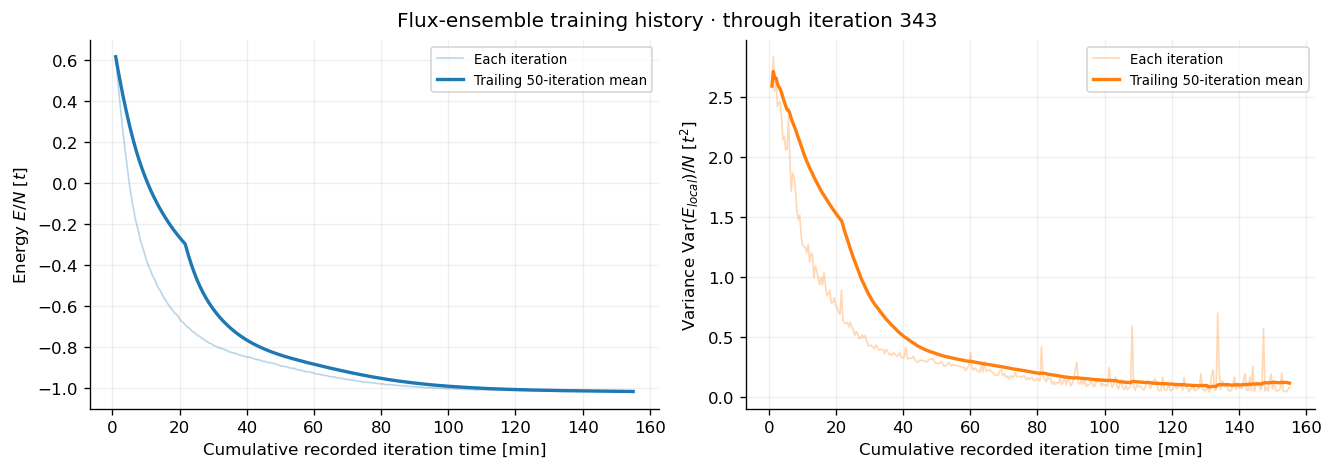

In [2]:
time_minutes = np.cumsum([h["total_seconds"] for h in history]) / 60
energy = np.array([h["ensemble_energy"] for h in history]) / N
variance = np.array([h["mean_variance"] for h in history]) / N

def trailing_mean(values, window=AVERAGE_ITERATIONS):
    sums = np.r_[0., np.cumsum(values)]
    end = np.arange(1, len(values) + 1)
    start = np.maximum(0, end - window)
    return (sums[end] - sums[start]) / (end - start)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, values, label, color in zip(axes, [energy, variance],
        [r"Energy $E/N$ [$t$]", r"Variance $\mathrm{Var}(E_{local})/N$ [$t^2$]"],
        ["tab:blue", "tab:orange"]):
    ax.plot(time_minutes, values, color=color, alpha=.3, lw=1, label="Each iteration")
    ax.plot(time_minutes, trailing_mean(values), color=color, lw=2, label=f"Trailing {AVERAGE_ITERATIONS}-iteration mean")
    ax.set(xlabel="Cumulative recorded iteration time [min]", ylabel=label)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle(f"Flux-ensemble training history · through iteration {latest}")
fig.savefig(OUT / "energy_variance_vs_time.png", bbox_inches="tight")
plt.show()

## Energy over the flux torus

Mean energy over the latest 50 completed iterations (or all available if fewer than 50), matching the structure-factor window. The exact iteration range is shown in the title. Finite-sample noise and incomplete optimization can produce visible departures from physical flux symmetries. Cells are centered at the actual twists; the $2\pi$ endpoint is not duplicated.

Energy heatmap: 50 iterations, 294–343


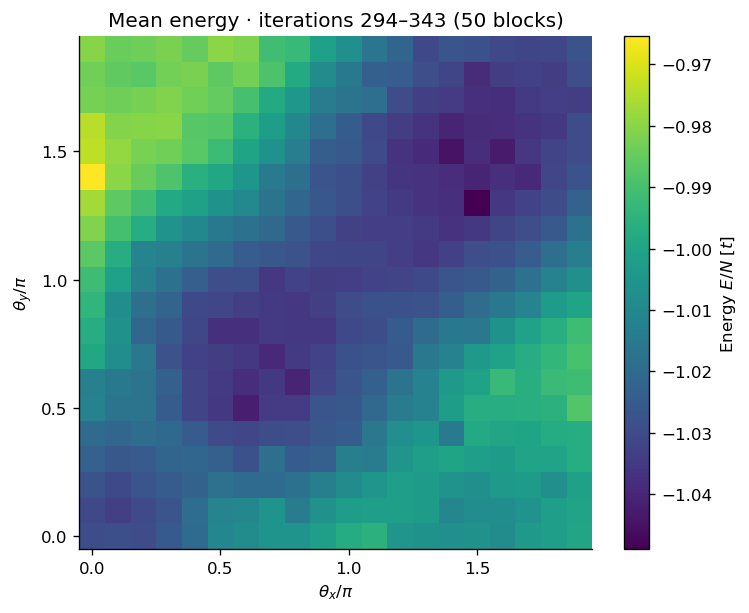

In [3]:
energy_window = [int(i) for i in iterations
                 if (RUN / "diagnostics" / f"step_{i:05d}.npz").exists()][-AVERAGE_ITERATIONS:]
energy_blocks = []
for iteration in energy_window:
    with np.load(RUN / "diagnostics" / f"step_{iteration:05d}.npz") as z:
        energy_blocks.append(z["energies"].copy())
energy_blocks = np.stack(energy_blocks)
grid = energy_blocks.mean(axis=0).reshape(len(flux_x), len(flux_y)) / N
np.savez_compressed(OUT / "energy_latest_window.npz", iterations=energy_window,
                    flux_x=flux_x, flux_y=flux_y, energy_blocks=energy_blocks,
                    mean_energy_per_site=grid, snapshot_iteration=latest)
print(f"Energy heatmap: {len(energy_window)} iterations, {energy_window[0]}–{energy_window[-1]}")
# pcolormesh expects rows along y and columns along x.
dx, dy = flux_x[1] - flux_x[0], flux_y[1] - flux_y[0]
xedges = np.r_[flux_x - dx/2, flux_x[-1] + dx/2] / np.pi
yedges = np.r_[flux_y - dy/2, flux_y[-1] + dy/2] / np.pi
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
mesh = ax.pcolormesh(xedges, yedges, grid.T, shading="flat", cmap="viridis")
fig.colorbar(mesh, ax=ax, label=r"Energy $E/N$ [$t$]")
ax.set(xlabel=r"$\theta_x/\pi$", ylabel=r"$\theta_y/\pi$",
       title=f"Mean energy · iterations {energy_window[0]}–{energy_window[-1]} ({len(energy_window)} blocks)", aspect="equal")
ax.set_xticks([0, .5, 1, 1.5]); ax.set_yticks([0, .5, 1, 1.5])
fig.savefig(OUT / "energy_flux_heatmap.png", bbox_inches="tight")
plt.show()

## Longitudinal spin structure factors

For each configuration, $S_i^z=(n_{i\uparrow}-n_{i\downarrow})/2$ and

$$S^{zz}(\mathbf{q})=\frac1N\sum_{ij}e^{i\mathbf{q}\cdot(\mathbf r_i-\mathbf r_j)}\langle S_i^zS_j^z\rangle
=\frac1N\left\langle\left|\sum_i e^{i\mathbf{q}\cdot\mathbf r_i}S_i^z\right|^2\right\rangle.$$

This includes the onsite term and uses the raw, unconnected correlator. Momenta are the 6×6 allowed lattice momenta, folded to $[-\pi,\pi)$. Twists couple to charge, so the gauge-invariant spin density uses the ordinary momentum grid. Balanced fixed spin populations imply $S^{zz}(0)=0$. All panels use the same color scale. The displayed average weights each saved sample equally and retains the original iteration blocks in the exported data.

In [4]:
distance = np.angle(np.exp(1j * (couplings[None, :, :] - REQUESTED_FLUX[:, None, :])))
point_indices = np.argmin(np.sum(distance**2, axis=-1), axis=1)
selected_flux = couplings[point_indices]
available = [int(i) for i in iterations if (RUN / "diagnostics" / f"step_{i:05d}.npz").exists()]
window = available[-SF_ITERATIONS:]
assert window, "No saved sample blocks available"
qaxes = [2*np.pi*np.fft.fftshift(np.fft.fftfreq(int(L))) for L in extent]
qx, qy = np.meshgrid(*qaxes, indexing="ij")
q = np.stack([qx.ravel(), qy.ravel()], axis=-1)
phase = np.exp(1j * (q @ coord.T))
# Keep per-iteration correlation tensors and raw sample blocks, without symmetry averaging.
correlation_blocks, structure_blocks, sample_counts, raw_spins = [], [], [], []
for iteration in window:
    with np.load(RUN / "diagnostics" / f"step_{iteration:05d}.npz") as z:
        spins = z["spins"][point_indices].copy()
    assert spins.shape[-1] == 2*N
    sz = (spins[..., :N].astype(float) - spins[..., N:].astype(float)) / 4
    np.testing.assert_allclose(sz.sum(axis=-1), 0., atol=1e-12)
    samples = spins.shape[1]
    corr = np.einsum("psi,psj->pij", sz, sz) / samples
    fourier = np.einsum("qi,psi->psq", phase, sz)
    sq = np.mean(np.abs(fourier)**2, axis=1) / N
    # Cross-check the Fourier estimator against the full real-space tensor.
    direct = np.einsum("qi,pij,qj->pq", phase, corr, phase.conj()).real / N
    np.testing.assert_allclose(sq, direct, atol=1e-12)
    # Momentum sum rule: sum_q S(q) = sum_i <(Sz_i)^2>.
    np.testing.assert_allclose(sq.sum(axis=1), np.trace(corr, axis1=1, axis2=2), atol=1e-12)
    correlation_blocks.append(corr)
    structure_blocks.append(sq)
    sample_counts.append(samples)
    raw_spins.append(spins)
correlation_blocks = np.stack(correlation_blocks)
structure_blocks = np.stack(structure_blocks)
sample_counts = np.asarray(sample_counts)
structure = np.average(structure_blocks, axis=0, weights=sample_counts)
print(f"SzSz window: {len(window)} completed iterations, {window[0]}–{window[-1]}; "
      f"{sample_counts.sum()} samples per flux point")
if len(window) < SF_ITERATIONS:
    print(f"Requested {SF_ITERATIONS} iterations; only {len(window)} are available. Re-run later to refresh.")
for wanted, actual in zip(REQUESTED_FLUX/np.pi, selected_flux/np.pi):
    print(f"Requested flux/pi {wanted.round(3)} -> plotted {actual.round(3)}")
np.savez_compressed(OUT / "szz_latest_window.npz", iterations=window,
    flux=selected_flux, point_indices=point_indices, q=q, coord=coord,
    sample_counts=sample_counts, raw_spins=np.stack(raw_spins),
    correlation_blocks=correlation_blocks, structure_blocks=structure_blocks,
    mean_structure=structure, snapshot_iteration=latest)
print("Passed: fixed total Sz, Fourier/tensor agreement, and momentum sum rule.")

SzSz window: 50 completed iterations, 294–343; 500 samples per flux point
Requested flux/pi [0. 0.] -> plotted [0. 0.]
Requested flux/pi [1. 0.] -> plotted [1. 0.]
Requested flux/pi [0. 1.] -> plotted [0. 1.]
Requested flux/pi [1. 1.] -> plotted [1. 1.]
Requested flux/pi [0.5 0.5] -> plotted [0.5 0.5]
Requested flux/pi [1.5 1.5] -> plotted [1.5 1.5]
Passed: fixed total Sz, Fourier/tensor agreement, and momentum sum rule.


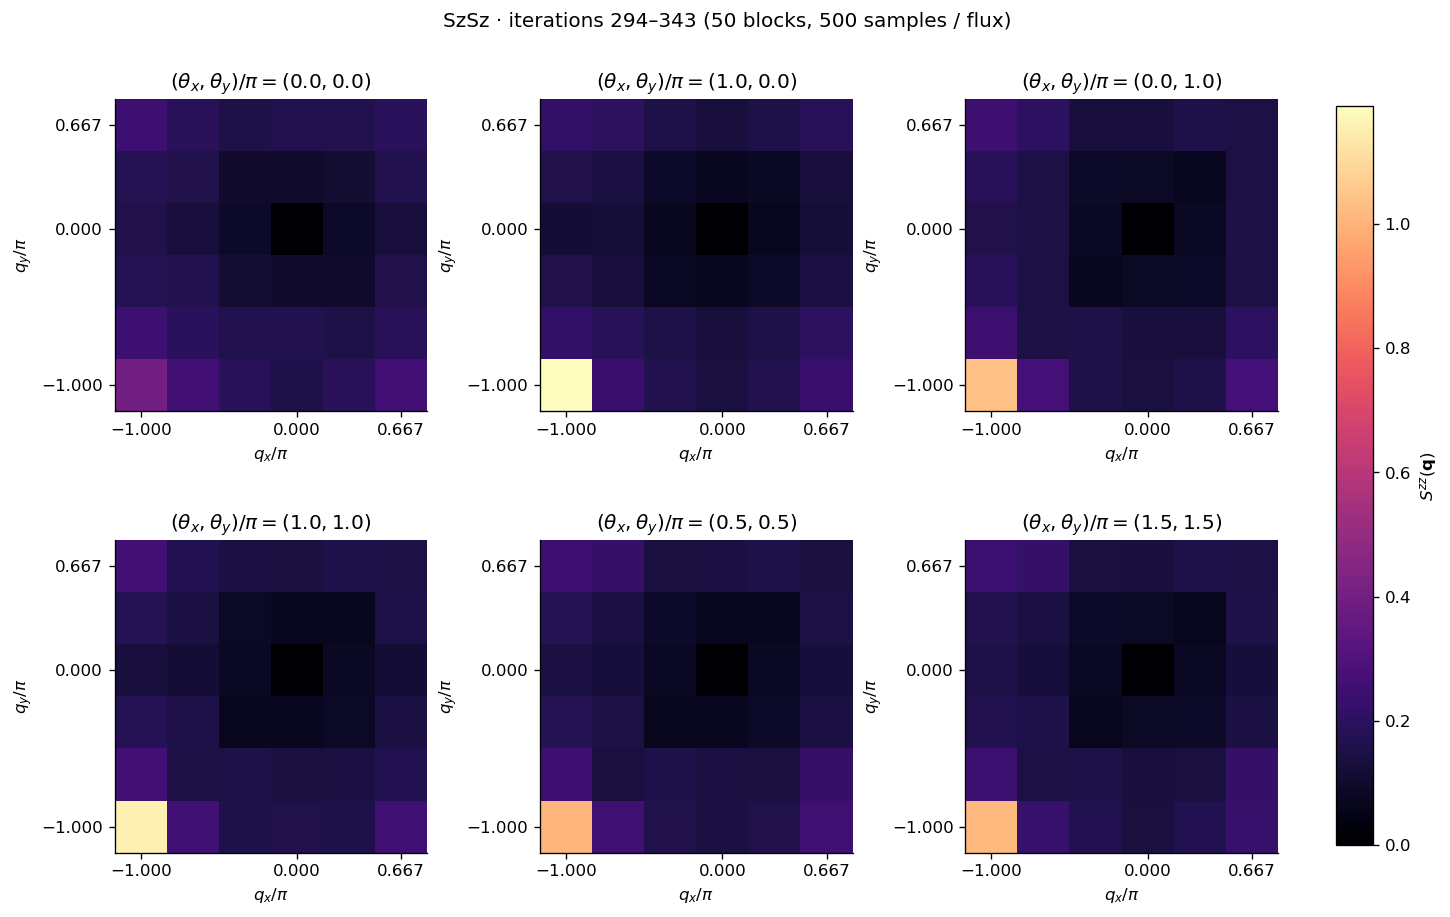

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6), constrained_layout=True)
vmax = float(structure.max())
qxedge = np.r_[qaxes[0] - np.pi/extent[0], qaxes[0][-1] + np.pi/extent[0]] / np.pi
qyedge = np.r_[qaxes[1] - np.pi/extent[1], qaxes[1][-1] + np.pi/extent[1]] / np.pi
for ax, sq, flux in zip(axes.flat, structure, selected_flux):
    mesh = ax.pcolormesh(qxedge, qyedge, sq.reshape(tuple(extent)).T,
                         cmap="magma", vmin=0, vmax=vmax, shading="flat")
    ax.set(title=fr"$(\theta_x,\theta_y)/\pi=({flux[0]/np.pi:.1f},{flux[1]/np.pi:.1f})$",
           xlabel=r"$q_x/\pi$", ylabel=r"$q_y/\pi$", aspect="equal")
    ax.set_xticks([-1, 0, 2/3]); ax.set_yticks([-1, 0, 2/3])
fig.colorbar(mesh, ax=axes.ravel().tolist(), label=r"$S^{zz}(\mathbf{q})$", shrink=.85)
fig.suptitle(f"SzSz · iterations {window[0]}–{window[-1]} "
             f"({len(window)} blocks, {sample_counts.sum()} samples / flux)")
fig.savefig(OUT / "szz_flux_points.png", bbox_inches="tight")
plt.show()

Figures are exported to `analysis/`. `szz_latest_window.npz` preserves selected raw spin configurations, full unsymmetrized real-space correlation tensors, structure factors for each temporal block, momenta, and the exact iteration window. Re-running overwrites these latest-window exports; the original per-iteration simulation samples remain in `calculation/run/diagnostics/`. These are training diagnostics; Markov correlations and ongoing optimization prevent interpreting the sample count as an independent equilibrium sample count.